# Вахта · модель опубликованных ставок

Один CatBoost оценивает ставку за смену, месяц или весь цикл. Единицу оплаты задаём при прогнозе. На выходе — центральная оценка P50 и калиброванный интервал с целевым покрытием 50%.

Ноутбук можно запустить сверху вниз, чтобы увидеть сохранённые результаты и сделать новый прогноз из весов. Последняя ячейка позволяет повторить обучение в отдельном каталоге. Пример прогноза не требует исходный CSV и использует вымышленную карточку.

**Что проверяем:** опубликованную ставку, с сохранением её налоговой базы и формы. Для «от X» прогнозируем заявленный минимум, для «до X» — максимум.

In [1]:
import json
import os
import subprocess
import sys
from datetime import datetime
from pathlib import Path

EXPERIMENT_REL = Path("ML/experiments/2026-11-25_vahta_model")
locations = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("VAHTA_REPO"):
    locations.insert(0, Path(os.environ["VAHTA_REPO"]).expanduser().resolve())
ROOT = next((p for p in locations if (p / EXPERIMENT_REL / "full_train.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из репозитория или задайте VAHTA_REPO.")

EXP = ROOT / EXPERIMENT_REL
RESULTS = EXP / "full_results"
VARIANT = "known_plausible_calibrated"
LOCAL_DEPS = ROOT / "ML" / ".cache" / "vahta-model-deps"
for folder in (LOCAL_DEPS, ROOT, EXP):
    if folder.is_dir() and str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

try:
    import pandas as pd
    import matplotlib.pyplot as plt
    from catboost import CatBoostRegressor
except ImportError as error:
    raise ImportError(f"Установите зависимости в ядро Python: %pip install -r \"{EXP / 'requirements.txt'}\"") from error

from IPython import get_ipython
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")
from full_data import target_quote
from full_predict import cat_predict
from full_shift import KNOWN_LIMITS, plausible_mask
from full_train import with_context
from train import CARD, extensions, make_features, sha256

weights = RESULTS / f"{VARIANT}.cbm"
if not weights.is_file():
    raise FileNotFoundError(f"Сохранённые результаты ожидаются в {RESULTS}")
print(f"Модель: {VARIANT} · Python {sys.version.split()[0]}")

Модель: known_plausible_calibrated · Python 3.12.0


## 1. Данные и разбор ставки

Ставка в карточке разбирается на границы, период, налоговую базу и форму. Для вилки цель — середина. Период из описания принимаем, если совпадает ставка и находится одна трактовка. Неопределённые или конфликтующие периоды остаются в самостоятельных срезах широкого прогона. Налоговую базу сохраняем: до налога, на руки, неизвестно или конфликт.

В рекомендуемой модели проверяем границы обеих сумм: за смену 300–50 000 ₽, за месяц 10 000–1 000 000 ₽, за цикл 3 000–2 000 000 ₽. Деления цикла на смены и умножения на 176 часов в этой постановке нет.

In [2]:
dataset = json.loads((RESULTS / "dataset.json").read_text(encoding="utf-8"))
labels = pd.read_csv(RESULTS / "labels.csv", dtype={"id": str})
unit_label = {
    "shift": "За смену", "month": "За месяц", "rotation": "За весь цикл",
    "hour": "За час", "duty_day": "За сутки", "unspecified": "Период неизвестен",
    "conflict": "Конфликт периода", "no_amount": "Без числовой ставки",
}
assert len(labels) == dataset["cards"] and labels.id.is_unique
assert labels.groupby("group").fold.nunique().max() == 1
print(f"Все карточки: {len(labels):,} · Числовые цели: {dataset['labeled']:,}".replace(",", " "))
inventory = labels.assign(Период=labels.unit.map(unit_label).fillna(labels.unit))
display(inventory.groupby("Период", sort=False).size().sort_values(ascending=False).rename("Карточек").to_frame())

Все карточки: 7 310 · Числовые цели: 7 269


,Карточек
Период,
Период неизвестен,5325
За смену,1686
За месяц,147
За весь цикл,69
Без числовой ставки,41
Конфликт периода,39
За сутки,2
За час,1


In [3]:
examples = [
    ("5 000 — 7 000 ₽ за смену на руки", ""),
    ("от 5 000 ₽ за смену на руки", ""),
    ("до 7 000 ₽ за смену на руки", ""),
    ("150 000 ₽ на руки", "150 000 ₽ за вахту на руки"),
    ("150 000 ₽ на руки", ""),
]
parsed_examples = []
for salary, description in examples:
    q, reason = target_quote(salary, extensions.extract(description))
    midpoint = (q["low"] + q["high"]) / 2 if q["shape"] == "range" else (
        q["high"] if q["shape"] == "to" else q["low"]
    )
    parsed_examples.append({
        "Ставка в карточке": salary, "Уточнение в описании": description,
        "Период": unit_label.get(q["unit"], q["unit"]), "Форма": q["shape"],
        "Налоговая база": q["tax"], "Цель, ₽": midpoint,
    })
display(pd.DataFrame(parsed_examples))

,Ставка в карточке,Уточнение в описании,Период,Форма,Налоговая база,"Цель, ₽"
0,5 000 — 7 000 ₽ за смену на руки,,За смену,range,net,6000.0
1,от 5 000 ₽ за смену на руки,,За смену,from,net,5000.0
2,до 7 000 ₽ за смену на руки,,За смену,to,net,7000.0
3,150 000 ₽ на руки,150 000 ₽ за вахту на руки,За весь цикл,exact,net,150000.0
4,150 000 ₽ на руки,,Период неизвестен,exact,net,150000.0


## 2. Признаки и обучение

В рекомендованной модели используются структурированные поля карточки и признаки из очищенного текста. Убираем зарплатные фрагменты, нормализуем HTML и похожие латинские буквы в русских словах. Признаки извлекаются правилами Кости, вахтовыми дополнениями и словарём условий M4. Условия поиска, ID объявления, имя работодателя и исходная сумма не подаются модели. Символьный и словный TF-IDF, а также отдельные NLP-признаки Кости проверены в альтернативных вариантах.

CatBoost обучает три квантиля логарифма ставки (120 итераций, глубина 4). Пять внешних фолдов разделены по связанным работодателям, профилям или точным дублям нормализованного описания. Внутри каждого обучающего фолда четверть групп отложена для настройки ширины интервала. Калибровка сохраняет P50.

In [4]:
columns = json.loads((RESULTS / f"{VARIANT}.columns.json").read_text(encoding="utf-8"))

def feature_block(name):
    if name in {"unit", "tax", "quote_kind"}:
        return "Контекст оплаты"
    if name in CARD or name == "military_type":
        return "Карточка Авито"
    if name.startswith(("rule_", "status_")):
        return "Правила Кости"
    if name.startswith("vahta_"):
        return "Вахтовые правила"
    if name.startswith(("cond_", "num_")):
        return "Условия из текста M4"
    return "Прочие"

features = pd.DataFrame({"Признак": columns, "Блок": [feature_block(c) for c in columns]})
print(f"Всего признаков: {len(features)}")
display(features.groupby("Блок", sort=False).agg(
    Признаков=("Признак", "size"), Примеры=("Признак", lambda names: ", ".join(names.head(4)))
))
# Для просмотра всех имён: display(features)
cb = CatBoostRegressor()
cb.load_model(str(weights))
importance = pd.Series(cb.get_feature_importance(), index=columns, name="Важность CatBoost, %")
display(importance.nlargest(10).round(2).to_frame())

Всего признаков: 189


,Признаков,Примеры
Блок,,
Карточка Авито,20,"profession_resolved, region, Занятость, Способ..."
Правила Кости,54,"rule_common__schedule_patterns, status_common_..."
Вахтовые правила,9,"vahta_status_paid_hours, vahta_paid_hours, vah..."
Условия из текста M4,103,"cond_pay_daily, cond_pay_weekly, cond_pay_twic..."
Контекст оплаты,3,"unit, tax, quote_kind"


,"Важность CatBoost, %"
unit,91.05
Сфера деятельности компании,1.80
profession_resolved,0.79
quote_kind,0.58
Количество рабочих часов в день,0.51
Длительность вахты,0.44
Объект,0.37
cond_perk_housing,0.36
cond_sch_vahta,0.33
cond_perk_dms,0.25


## 3. Метрики и выбор модели

MAPE — средняя абсолютная процентная ошибка прогноза P50. Медианная ошибка показывает типичный промах. Покрытие — доля ставок, попавших в интервал с номинальной целью 50%. Значения берутся из прогнозов для отложенных групп.

В широком прогоне среди 7 269 числовых целей есть шумные ставки и суммы без периода. Для сравнения вариантов на широком наборе смотрим на медианную ошибку, покрытие и ошибку по квантилям (pinball loss).

,Карточек,MAPE базы,MAPE модели,Медианная ошибка,Покрытие
За смену,1477,25.1%,21.5%,16.2%,50.7%
За месяц,146,30.5%,23.2%,16.6%,37.7%
За весь цикл,69,34.4%,23.1%,20.2%,43.5%
Три единицы вместе,1692,25.9%,21.7%,16.5%,49.3%


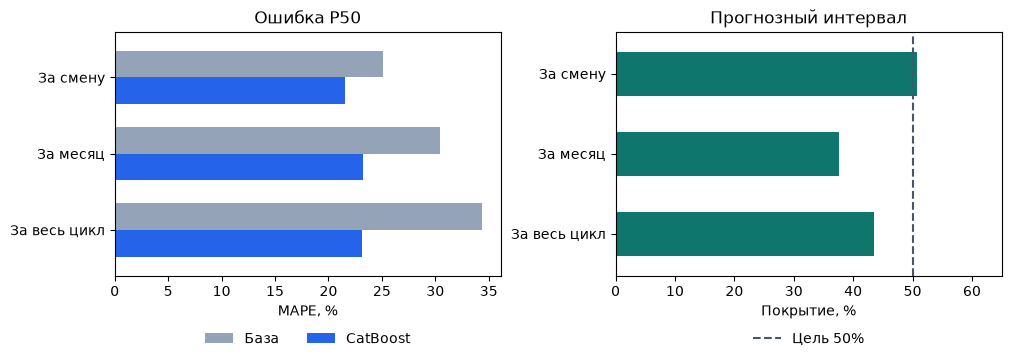

In [5]:
benchmark_units = ["shift", "month", "rotation"]
oof = pd.read_csv(RESULTS / "known_plausible_oof.csv", dtype={"id": str})
oof = oof[oof.unit.isin(benchmark_units)].copy()
assert oof.groupby("group").fold.nunique().max() == 1
assert not oof.duplicated(["id", "variant"]).any()
oof["ape"] = (oof.y - oof.p50).abs() / oof.y
oof["inside"] = oof.y.between(oof.p25, oof.p75)
model_oof = oof[oof.variant.eq("rules_plausible_calibrated")]
base_oof = oof[oof.variant.eq("empirical")]
summary = model_oof.groupby("unit").agg(
    n=("id", "size"), mape=("ape", "mean"), median=("ape", "median"), coverage=("inside", "mean")
).reindex(benchmark_units)
summary["base_mape"] = base_oof.groupby("unit").ape.mean()
summary.loc["all"] = [
    len(model_oof), model_oof.ape.mean(), model_oof.ape.median(),
    model_oof.inside.mean(), base_oof.ape.mean()
]
shown = summary[["n", "base_mape", "mape", "median", "coverage"]].copy()
shown["n"] = shown.n.astype(int)
shown.index = [unit_label.get(key, "Три единицы вместе") for key in shown.index]
shown.columns = ["Карточек", "MAPE базы", "MAPE модели", "Медианная ошибка", "Покрытие"]
display(shown.style.format({name: "{:.1%}" for name in shown.columns[1:]}))

chart = summary.loc[benchmark_units, ["base_mape", "mape", "coverage"]] * 100
chart.index = [unit_label[key] for key in chart.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
chart[["base_mape", "mape"]].rename(columns={"base_mape": "База", "mape": "CatBoost"}).plot.barh(
    ax=ax1, color=["#94a3b8", "#2563eb"], width=.7
)
ax1.set(xlabel="MAPE, %", ylabel="", title="Ошибка P50")
ax1.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=2, frameon=False)
chart.coverage.plot.barh(ax=ax2, color="#0f766e", width=.55)
goal = ax2.axvline(50, color="#475569", linestyle="--", label="Цель 50%")
ax2.set(xlim=(0, 65), xlabel="Покрытие, %", ylabel="", title="Прогнозный интервал")
ax2.legend(handles=[goal], loc="upper center", bbox_to_anchor=(.5, -.18), frameon=False)
for ax in (ax1, ax2):
    ax.invert_yaxis()
plt.show()

In [6]:
wide = pd.read_csv(RESULTS / "metrics.csv")
names = {
    "empirical": "База по профессии и типу ставки", "card": "CatBoost: карточка",
    "rules": "CatBoost: карточка + правила", "rules_nlp": "CatBoost: правила + NLP",
    "card_char": "CatBoost: карточка + символьный TF-IDF",
    "full_text": "CatBoost: правила, NLP, символьный и словный TF-IDF",
    "specialists": "Отдельные CatBoost по единицам", "ridge": "Ridge",
    "blend": "Ансамбль CatBoost/Ridge",
}
table = wide.loc[wide.dimension.eq("total"), ["variant", "n", "median_ape", "coverage", "pinball_log"]].copy()
table.variant = table.variant.map(names)
table.columns = ["Модель", "Карточек с прогнозом", "Медианная ошибка", "Покрытие", "Pinball loss"]
display(table.sort_values("Pinball loss").reset_index(drop=True).style.format({
    "Медианная ошибка": "{:.1%}", "Покрытие": "{:.1%}", "Pinball loss": "{:.4f}",
}))
cycle = wide.loc[wide.dimension.eq("unit") & wide.key.eq("rotation") & wide.variant.eq("card_char")].iloc[0]
print(f"Вариант с символьным TF-IDF за цикл: {cycle.mape:.1%} MAPE, {cycle.coverage:.1%} покрытия, {cycle.n} карточек.")

,Модель,Карточек с прогнозом,Медианная ошибка,Покрытие,Pinball loss
0,Отдельные CatBoost по единицам,7269,17.0%,45.2%,0.1679
1,CatBoost: карточка + символьный TF-IDF,7269,17.2%,49.4%,0.1684
2,"CatBoost: правила, NLP, символьный и словный TF-IDF",7269,17.2%,46.6%,0.1689
3,CatBoost: карточка + правила,7269,16.9%,47.8%,0.1696
4,CatBoost: правила + NLP,7269,17.1%,47.2%,0.1697
5,CatBoost: карточка,7269,17.2%,48.2%,0.1703
6,Ансамбль CatBoost/Ridge,7269,22.0%,55.2%,0.1805
7,База по профессии и типу ставки,7268,20.0%,50.1%,0.1890
8,Ridge,7269,31.1%,51.2%,0.2168


Вариант с символьным TF-IDF за цикл: 21.9% MAPE, 50.7% покрытия, 69 карточек.


**Что брать в пилот.** Для смены — калиброванный CatBoost с правилами. Для месяца и цикла точечный прогноз остаётся экспериментальным: выборки небольшие, интервалы недокрывают. Вариант с символьным TF-IDF для цикла стоит перепроверить на новых данных. Если период неизвестен, не выдаём оценку в ₽/смену или ₽/месяц.

Общий результат на трёх сопоставимых срезах относится к 1 692 из 7 310 вахтовых карточек. Нового временного среза для проверки пока нет.

## 4. Прогноз из сохранённых весов

Ниже вымышленная карточка без опубликованной суммы. Можно заменить условия и запросить ставку за смену, месяц или цикл. Контекст формы и налога тоже задаётся явно. Число примеров с таким контекстом выводится для ориентира; оно включает обучающий срез до внутреннего разделения на обучение и калибровку.

In [7]:
request = {"unit": "shift", "tax": "net", "quote_kind": "central"}
example = {key: "" for key in CARD}
example.update({
    "title": "Комплектовщик на склад, работа вахтой",
    "description": "Вахта 30 рабочих смен. Смена 11 часов, предоставляем проживание и питание. Комплектация заказов с ТСД.",
    "Что получают работники": "Проживание, Питание",
    "profession_resolved": "Комплектовщик",
    "Сфера деятельности компании": "Логистика",
    "Количество рабочих часов в день": "11",
    "Смены": "Дневные",
    "Длительность вахты": "30 смен",
})
example_df = pd.DataFrame([example])
supported = plausible_mask(labels, KNOWN_LIMITS)
for key, value in request.items():
    supported &= labels[key].eq(value)
if not supported.any():
    raise ValueError(f"В обучающем срезе нет такого контекста: {request}")

x, _ = make_features(example_df)
x["military_type"] = pd.Series("no", index=x.index, dtype=object)
x = with_context(x, pd.DataFrame([request]))
p = cat_predict(RESULTS, VARIANT, x, pd.Series([""], index=x.index))[0]
assert 0 < p[0] <= p[1] <= p[2]
display(pd.DataFrame([{
    "Единица": unit_label[request["unit"]], "Налоговая база": request["tax"],
    "Форма ставки": request["quote_kind"], "Нижняя граница, ₽": round(p[0]),
    "P50, ₽": round(p[1]), "Верхняя граница, ₽": round(p[2]),
    "Похожий контекст, карточек": int(supported.sum()),
}]))

,Единица,Налоговая база,Форма ставки,"Нижняя граница, ₽","P50, ₽","Верхняя граница, ₽","Похожий контекст, карточек"
0,За смену,net,central,4525,5349,6439,548


## 5. Переобучение по желанию

Поставьте `MODE = "recommended"`, чтобы подготовить данные и переобучить рекомендуемый вариант. `MODE = "all"` дополнительно повторит широкое сравнение моделей, NLP и эксперимент только на смене. На CPU полный запуск занимает несколько минут. Скрипты живут рядом с ноутбуком, чтобы отчёт и код обучения использовали одни и те же правила.

Новые результаты пишутся в отдельную папку. Сохранённые результаты выше используются до явного переключения на новую папку.

In [8]:
MODE = "saved"  # "saved", "recommended" или "all"
if MODE not in {"saved", "recommended", "all"}:
    raise ValueError("Неизвестный режим запуска")

if MODE == "saved":
    print("Использованы сохранённые результаты. Для обучения измените MODE.")
else:
    run = ROOT / "ML" / ".cache" / "vahta_runs" / f"vahta-notebook-{datetime.now():%Y%m%d-%H%M%S-%f}"
    run.mkdir(parents=True)
    snapshot = ROOT / "Data" / "dataset" / "vacancies.csv"
    if not snapshot.is_file():
        from utils.build_dataset import assemble
        manifest = json.loads((ROOT / "Data/dataset/manifest.json").read_text(encoding="utf-8"))
        def read_blob(path):
            return subprocess.check_output(["git", "show", f"HEAD:Data/dataset/{path}"], cwd=ROOT)
        snapshot = run / "vacancies.csv"
        snapshot.write_bytes(assemble(manifest, read_blob))
    if sha256(snapshot) != dataset["sha256"]:
        raise ValueError("SHA-256 отличается от сохранённого эксперимента. Проверьте снимок данных.")

    cache, out = run / "cache", run / "results"
    env = os.environ.copy()
    if LOCAL_DEPS.is_dir():
        env["PYTHONPATH"] = os.pathsep.join(filter(None, [str(LOCAL_DEPS), env.get("PYTHONPATH")]))
    def run_script(script, *args):
        subprocess.run([sys.executable, "-X", "utf8", str(EXP / script), *map(str, args)],
                       cwd=ROOT, env=env, check=True)
    extra = ["--without-nlp"] if MODE == "recommended" else []
    run_script("full_data.py", "--data", snapshot, "--out", cache, *extra)
    if MODE == "all":
        run_script("full_train.py", "--cache", cache, "--out", out)
        run_script("full_shift.py", "--cache", cache, "--out", out)
    run_script("full_shift.py", "--cache", cache, "--out", out, "--known-units")
    if MODE == "recommended":
        import shutil
        for file in ("labels.csv", "dataset.json"):
            shutil.copyfile(cache / file, out / file)
    print(f"Новые веса и метрики: {out}")
    retrained = pd.read_csv(out / "known_plausible_metrics.csv")
    display(retrained.loc[retrained.variant.eq("rules_plausible_calibrated") &
                          retrained.quote_kind.str.startswith("unit:"),
                          ["quote_kind", "n", "mape", "median_ape", "coverage"]])

Использованы сохранённые результаты. Для обучения измените MODE.
